In [8]:
import numpy as np
import math
import sys
import time
import matplotlib.pyplot as plt

### Demo: An Experiment on Exploiting the Diagonal plus Low Rank Structure

In the text book {book-convex-2004}, section 9.7, when implementing the Newton method, it was proposed to exploit the structure of the Hessian matrix to accelerate the calculation of the Newton steps from the normal equation, i.e.,$H\Delta x_{nt} = -g$.

One of the types of structures is the \textit{diagonal plus low rank}, in which the Hessian $H$ can be expressed as a diagonal matrix plus low rank, $p$, typically occurring in the following form of objective function,
$$
f(x) = \displaystyle{\sum_{i=1}^{n}\psi_i(x_i)} + \psi_0(Ax+b)
$$
where, $A\in R^{p\times n}$, $\psi_i, ...,\psi_n:R\rightarrow R$, and $\psi_0:R^p\rightarrow R$.
By exploiting the structure, the solution of Newton steps can be calculated in the following steps:
\begin{itemize}
\item Let $D=\mathbf{diag}(\psi_1''(x_1), ...,\psi_n''(x_n))$
\item Let $H_0=\nabla^2 \psi_0(Ax+b)$
\item Let $H_0=L_0L_0^T$ be the Cholesky factorization of $H_0$
\item Compute $w$ by solving $p$ linear equations: $(I+L_0^TAD^{-1}A^TL_0)w=-L_0^TAD^{-1}g$
\item Compute $\Delta x_{nt}=-D^{-1}(A^TL_0w+g)$
\end{itemize}

The total cost of computing $\Delta x_{nt}$ is dominated by $2p^2n$, which is far smaller than $(1/3)n^3$ in solving the normal equation in a straightforward method without exploiting the structure when $p\ll n$.

In this experiment, let 
$$\psi_0=(1/2)(Ax+b)^TP(Ax+b), \psi_i=e^{-(c_ix_i+d_i)}, i=1,...,n, $$

Accordingly,
$$
\begin{array}{rclrcl}
g & = & [..., -c_ie^{-(c_ix_i+d_i)}, ...]^T+A^TP(Ax+b), &
H_0 & = & P, \\
D & = & \mathbf{diag}(..., c_i^2e^{-(c_ix_i+d_i)}, ...), &
H & = & D + A^TH_0A \\
\end{array}
$$

To make the problem feasible and lower bounded, the parameters $A, b, c, d$ are selected in the following steps to satisfy $\nabla f(x^*)=0$ at $x^*=0$,
\begin{itemize}
\item Let $A=[a_{i,j}], b=[b_{i}], c=[c_{j}]$ with $a_{i,j}, b_{i}, c_{j}\in(0,1)$ randomly
\item Let $P$ be positive definite
\item Let $d=-log(\dfrac{A^TPb}{c})$
\end{itemize}

The first experiment result shows and compares the averaging computation time to solve the minimization problem using Newton method when $n=1000$, and $p=2^k,k=1,2,...,$.

More details on the setup of the demo in Jupiter notebook for practice can be accessed from the Lecture's JupyterLab webpage:

[JupyterLab webpage](https://wuzhuchun.club:9091/lab/tree/welcome.ipynb}{https://wuzhuchun.club:9091/lab/tree/welcome.ipynb).


In [9]:
def my_f(x, c, d, P, A, b):
    n = len(x)
    f_v = 0
    for i in range(n):
        xi = x[i, 0]
        ci = c[i, 0]
        di = d[i, 0]
        psi_i = math.exp(-(ci * xi + di))
        f_v = f_v + psi_i
    y = A @ x + b
    psi_0 = 0.5 * ((y.T @ P @ y).item())
    f_v = f_v + psi_0
    return f_v


def my_gradient_f(x, c, d, P, A, b):
    n = len(x)
    psi_gradient = np.zeros((n, 1))
    for i in range(n):
        xi = x[i, 0]
        ci = c[i, 0]
        di = d[i, 0]
        psi_gradient_i = math.exp(-(ci * xi + di)) * (-ci)
        psi_gradient[i, 0] = psi_gradient_i

    gradient = psi_gradient + A.T @ P @ (A @ x + b)
    return gradient


def my_hessian_f(x, c, d, P, A, b):
    n = len(x)
    psi_hessian = np.zeros((n, 1))
    for i in range(n):
        xi = x[i, 0]
        ci = c[i, 0]
        di = d[i, 0]
        psi_hessian_i = math.exp(-(ci * xi + di)) * (ci ** 2)
        psi_hessian[i, 0] = psi_hessian_i

    hessian = np.diag(np.squeeze(psi_hessian)) + A.T @ P.T @ A
    return hessian

In [10]:
def my_newton_step_decrement(x, args):
    gradient = my_gradient_f(x, *args)
    hessian = my_hessian_f(x, *args)
    if np.linalg.cond(hessian) < 1 / sys.float_info.epsilon:
        hessian_inv = np.linalg.inv(hessian)
        x_nt = -1 * hessian_inv @ gradient
        decrement = -1 * gradient.T @ x_nt
        return x_nt, decrement.item()
    else:
        raise RuntimeError("inversion of hessian failed")

In [11]:
def my_newton_step_decrement_opt(x, args):
    (c, d, P, A, b) = args
    n = len(x)
    p = len(b)

    psi_hessian = np.zeros((n, 1))
    for i in range(n):
        xi = x[i, 0]
        ci = c[i, 0]
        di = d[i, 0]
        psi_hessian_i = math.exp(-(ci * xi + di)) * (ci ** 2)
        psi_hessian[i, 0] = psi_hessian_i
    D_inv = np.diag(np.squeeze( 1 / psi_hessian))

    g = my_gradient_f(x, *args)
    H0 = P
    L0 = np.linalg.cholesky(H0)

    B = np.identity(p) + L0.T @ A @ D_inv @ A.T @ L0
    w = np.linalg.inv(B) @ (-L0.T @ A @ D_inv @ g)
    x_nt = -D_inv @ (A.T @ L0 @ w + g)
    decrement = -1 * g.T @ x_nt
    return x_nt, decrement.item()

In [12]:
def backtracking_line_search(f, df, x, delta_x, alpha, beta, args):
    t = 1
    try:
        while f(x + delta_x * t, *args) > f(x, *args) + alpha * t * ((df(x, *args).T @ delta_x).item()):
            t = beta * t
        return t
    except:
        print('Error')

In [13]:
def plot_compare_profiling(p_s, n_epoch):
    n_p = len(p_s)
    n_seed = n_epoch
    n = 1024

    elapse_time_log = np.zeros((2, n_p, n_seed))
    methods = [my_newton_step_decrement, my_newton_step_decrement_opt]
    for method_i in range(len(methods)):
        newton_step_decrement_f = methods[method_i]
        for p_i in range(n_p):
            p = p_s[p_i]
            for seed in range(n_seed):
                np.random.seed(seed)
                start_time = time.time()
                A = np.random.rand(p, n)
                if not np.linalg.matrix_rank(A) == p:
                    raise RuntimeError("rank(A) should be full rank!")
                b = np.random.rand(p, 1)

                B = np.random.rand(p, p)
                if not np.linalg.matrix_rank(B) == p:
                    raise RuntimeError("rank(B) should be full rank!")

                P = B @ B.T  # so that P is positive
                c = np.random.rand(n, 1)
                d = -1 * np.log((A.T @ P @ b) / c)
                args = (c, d, P, A, b)
                epsilon = 1e-10
                alpha = 0.01
                beta = 0.5

                x0 = np.ones((n, 1))
                x = x0
                x_nt, decrement = newton_step_decrement_f(x, args)
                fx = []
                tx = []
                fx.append(my_f(x, *args))
                iterations = 0
                while decrement / 2 > epsilon:
                    t = backtracking_line_search(my_f, my_gradient_f, x, x_nt, alpha, beta, args)
                    tx.append(t)
                    x_next = x + t * x_nt
                    x = x_next
                    x_nt, decrement = newton_step_decrement_f(x, args)
                    fx.append(my_f(x, *args))
                    iterations = iterations + 1

                stop_time = time.time()
                elapse_time = stop_time - start_time
                #print("Info: --- %s seconds ---" % elapse_time)
                elapse_time_log[method_i, p_i, seed] = elapse_time

    elapse_time = elapse_time_log
    (M, Np, Ns) = elapse_time.shape
    elapse_time_avg = np.average(elapse_time, axis=2)
    ax = plt.subplot(1, 1, 1)
    ax.semilogx(p_s, elapse_time_avg[0, :], marker='s', fillstyle='none', base=2, linestyle='dashed',
                label='without exploiting the structure')
    ax.semilogx(p_s, elapse_time_avg[1, :], marker='o', fillstyle='none', linestyle='dashed', base=2,
                label='exploiting the diagonal plus low rank structure')
    ax.grid()
    ax.legend()
    ax.set_xlabel('p')
    ax.set_ylabel('elaspse time (second)')
    ax.set_title('Elapse time for the Newton method')
    plt.show()

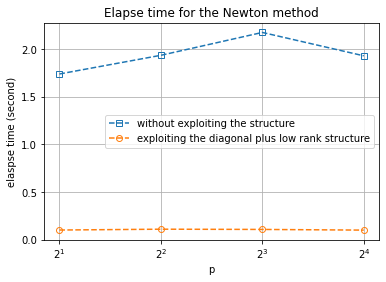

In [14]:
if __name__ == "__main__":
    p_s = [2, 4, 8, 16]
    n_epoch = 4
    plot_compare_profiling(p_s=p_s, n_epoch=n_epoch)